In [3]:
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import optuna

from sklearn.model_selection import KFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from lightgbm import LGBMRegressor

from features import clean_data, add_features, NUMERIC_FEATURES, CATEGORICAL_FEATURES, FEATURES, TARGET

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
optuna.logging.set_verbosity(optuna.logging.WARNING)

/Users/akmaralazhimamatova/Desktop/Final Project DS/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
raw = pd.read_csv("data/historical_data.csv")
print(raw.shape)
raw.head()

(197428, 16)


,market_id,created_at,actual_delivery_time,store_id,store_primary_category,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_dashers,total_busy_dashers,total_outstanding_orders,estimated_order_place_duration,estimated_store_to_consumer_driving_duration
0,1.0,2015-02-06 22:24:17,2015-02-06 23:27:16,1845,american,1.0,4,3441,4,557,1239,33.0,14.0,21.0,446,861.0
1,2.0,2015-02-10 21:49:25,2015-02-10 22:56:29,5477,mexican,2.0,1,1900,1,1400,1400,1.0,2.0,2.0,446,690.0
2,3.0,2015-01-22 20:39:28,2015-01-22 21:09:09,5477,NaN,1.0,1,1900,1,1900,1900,1.0,0.0,0.0,446,690.0
3,3.0,2015-02-03 21:21:45,2015-02-03 22:13:00,5477,NaN,1.0,6,6900,5,600,1800,1.0,1.0,2.0,446,289.0
4,3.0,2015-02-15 02:40:36,2015-02-15 03:20:26,5477,NaN,1.0,3,3900,3,1100,1600,6.0,6.0,9.0,446,650.0


In [5]:
raw.info()

missing = raw.isna().sum()
pd.DataFrame({"missing": missing, "percent": (missing / len(raw) * 100).round(2)}).query("missing > 0")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 197428 entries, 0 to 197427
Data columns (total 16 columns):
 #   Column                                        Non-Null Count   Dtype  
---  ------                                        --------------   -----  
 0   market_id                                     196441 non-null  float64
 1   created_at                                    197428 non-null  object 
 2   actual_delivery_time                          197421 non-null  object 
 3   store_id                                      197428 non-null  int64  
 4   store_primary_category                        192668 non-null  object 
 5   order_protocol                                196433 non-null  float64
 6   total_items                                   197428 non-null  int64  
 7   subtotal                                      197428 non-null  int64  
 8   num_distinct_items                            197428 non-null  int64  
 9   min_item_price                                19

,missing,percent
market_id,987,0.50
actual_delivery_time,7,0.00
store_primary_category,4760,2.41
order_protocol,995,0.50
total_onshift_dashers,16262,8.24
total_busy_dashers,16262,8.24
total_outstanding_orders,16262,8.24
estimated_store_to_consumer_driving_duration,526,0.27


In [6]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
market_id,196441.0,2.978706,1.524867,1.0,2.0,3.0,4.0,6.0
store_id,197428.0,3530.510272,2053.496711,1.0,1686.0,3592.0,5299.0,6987.0
order_protocol,196433.0,2.882352,1.503771,1.0,1.0,3.0,4.0,7.0
total_items,197428.0,3.196391,2.666546,1.0,2.0,3.0,4.0,411.0
subtotal,197428.0,2682.331402,1823.093688,0.0,1400.0,2200.0,3395.0,27100.0
num_distinct_items,197428.0,2.670791,1.630255,1.0,1.0,2.0,3.0,20.0
min_item_price,197428.0,686.218470,522.038648,-86.0,299.0,595.0,949.0,14700.0
max_item_price,197428.0,1159.588630,558.411377,0.0,800.0,1095.0,1395.0,14700.0
total_onshift_dashers,181166.0,44.808093,34.526783,-4.0,17.0,37.0,65.0,171.0
total_busy_dashers,181166.0,41.739747,32.145733,-5.0,15.0,34.0,62.0,154.0


In [7]:
target_raw = (pd.to_datetime(raw["actual_delivery_time"]) - pd.to_datetime(raw["created_at"])).dt.total_seconds() / 60
target_raw.describe(percentiles=[0.01, 0.5, 0.95, 0.99, 0.999]).round(1)

count    197421.0
mean         48.5
std         320.5
min           1.7
1%           19.2
50%          44.3
95%          81.2
99%         107.9
99.9%       165.6
max      141947.6
dtype: float64

In [8]:
df = clean_data(raw)
removed = len(raw) - len(df)
print(f"Before: {len(raw):,}  After: {len(df):,}  Removed: {removed:,} ({removed / len(raw):.2%})")

Before: 197,428  After: 197,283  Removed: 145 (0.07%)


In [9]:
df = add_features(df)
df[FEATURES + [TARGET]].head()

,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,avg_item_price,price_range,total_onshift_dashers,total_busy_dashers,total_outstanding_orders,...,orders_per_dasher,est_place_min,est_driving_min,hour,day_of_week,is_weekend,market_id,order_protocol,store_primary_category,delivery_minutes
0,2,1058,2,219.0,799,529.000000,580.0,2.0,1.0,1.0,...,0.500000,4.183333,7.716667,15,2,0,1,4,dessert,55.666667
1,2,690,2,195.0,255,345.000000,60.0,2.0,0.0,1.0,...,0.500000,4.183333,7.633333,15,2,0,3,4,cafe,44.716667
2,3,1867,3,449.0,529,622.333333,80.0,4.0,1.0,1.0,...,0.250000,4.183333,4.733333,15,2,0,1,4,smoothie,18.916667
3,3,955,3,245.0,345,318.333333,100.0,3.0,2.0,2.0,...,0.666667,4.183333,6.283333,15,2,0,1,4,cafe,41.916667
4,3,825,1,125.0,125,275.000000,0.0,0.0,0.0,0.0,...,NaN,4.183333,8.900000,15,2,0,1,3,chinese,53.683333


In [10]:
df[FEATURES].isna().sum()[lambda s: s > 0]

min_item_price                 13
price_range                    13
total_onshift_dashers       16269
total_busy_dashers          16269
total_outstanding_orders    16292
available_dashers           16289
busy_ratio                  19890
orders_per_dasher           19914
est_driving_min               526
dtype: int64

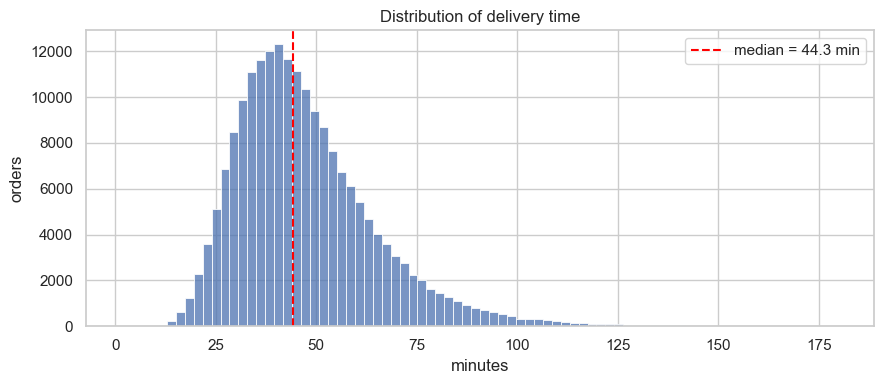

count    197283.0
mean         47.5
std          18.0
min           1.7
25%          35.1
50%          44.3
75%          56.3
max         179.8
Name: delivery_minutes, dtype: float64


In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(df[TARGET], bins=80, ax=ax)
ax.axvline(df[TARGET].median(), color="red", linestyle="--", label=f"median = {df[TARGET].median():.1f} min")
ax.set(title="Distribution of delivery time", xlabel="minutes", ylabel="orders")
ax.legend()
plt.tight_layout()
plt.savefig("figures/01_target_distribution.png", dpi=120)
plt.show()

print(df[TARGET].describe().round(1))



median 44.3 min, mean 47.5 min, and 67% of orders take 30–60 min. 
The distribution is right-skewed, with a long tail of slow orders, so the mean is above the median. That's why RMSE (sensitive to big misses).

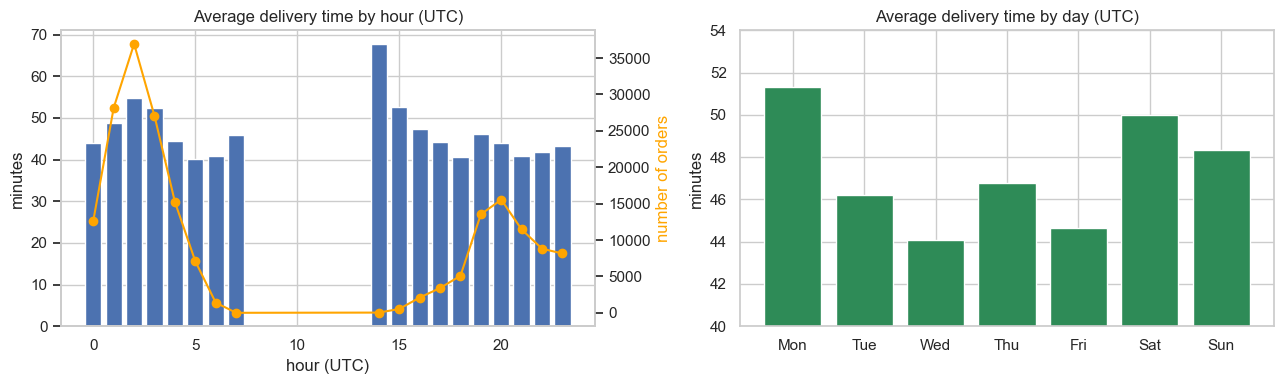

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

by_hour = df.groupby("hour")[TARGET].agg(["mean", "size"])
axes[0].bar(by_hour.index, by_hour["mean"])
axes[0].set(title="Average delivery time by hour (UTC)", xlabel="hour (UTC)", ylabel="minutes")
ax2 = axes[0].twinx()
ax2.plot(by_hour.index, by_hour["size"], color="orange", marker="o")
ax2.set_ylabel("number of orders", color="orange")
ax2.grid(False)

days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_day = df.groupby("day_of_week")[TARGET].mean()
axes[1].bar([days[i] for i in by_day.index], by_day.values, color="seagreen")
axes[1].set(title="Average delivery time by day (UTC)", ylabel="minutes", ylim=(40, 54))

plt.tight_layout()
plt.savefig("figures/02_time_patterns.png", dpi=120)
plt.show()

most orders arrive at 01:00–03:00 UTC, which is US dinner time (around 17:00-19:00 Pacific). The busiest hours are also slower. There are no orders at 08:00-13:00 UTC because it's night in the US. Days are in UTC too: "Monday" early-UTC hours are Sunday evening in the US, which explains why Monday looks slowest.

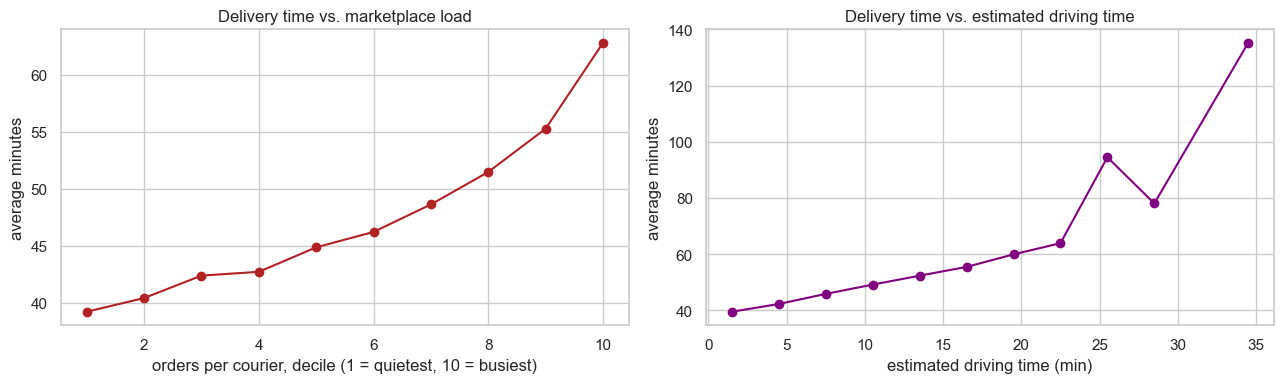

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

tmp = df.dropna(subset=["orders_per_dasher"]).copy()
tmp["load_decile"] = pd.qcut(tmp["orders_per_dasher"], 10, labels=range(1, 11))
load = tmp.groupby("load_decile", observed=True)[TARGET].mean()
axes[0].plot(load.index.astype(int), load.values, marker="o", color="firebrick")
axes[0].set(title="Delivery time vs. marketplace load",
            xlabel="orders per courier, decile (1 = quietest, 10 = busiest)", ylabel="average minutes")

tmp2 = df.dropna(subset=["est_driving_min"]).copy()
tmp2["drive_bin"] = pd.cut(tmp2["est_driving_min"], bins=range(0, 40, 3))
drive = tmp2.groupby("drive_bin", observed=True)[TARGET].mean()
axes[1].plot([b.mid for b in drive.index], drive.values, marker="o", color="purple")
axes[1].set(title="Delivery time vs. estimated driving time",
            xlabel="estimated driving time (min)", ylabel="average minutes")

plt.tight_layout()
plt.savefig("figures/03_load_and_distance.png", dpi=120)
plt.show()

from the quietest 10% of moments to the busiest 10%, the average delivery rises from 39 to 63 minutes. The curve bends upward, so the effect is non-linear. A longer drive also means a longer delivery (about 39 → 64 min for 0–22 min of driving). Beyond ~22 min there are very few orders, so the right end is noisy.

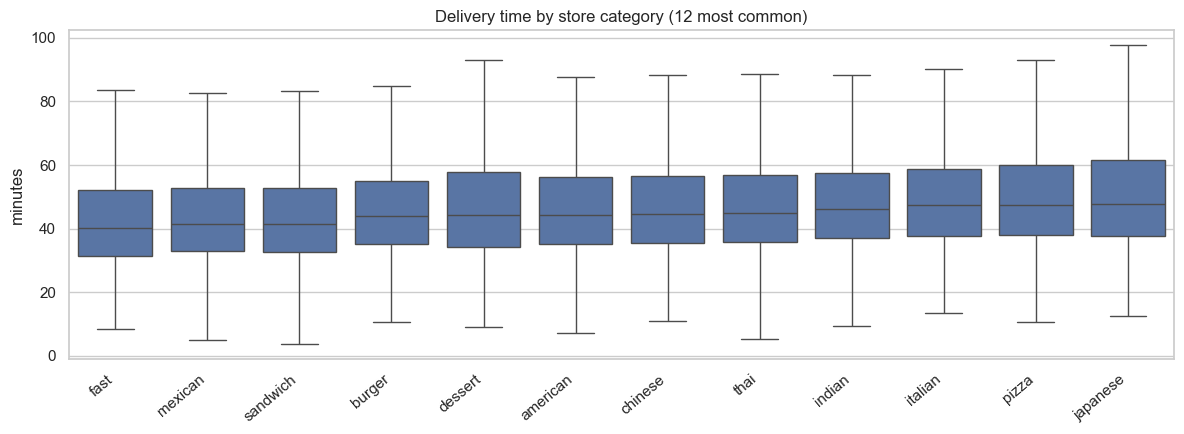

In [14]:
top = df["store_primary_category"].value_counts().head(12).index
sub = df[df["store_primary_category"].isin(top)]
order = sub.groupby("store_primary_category")[TARGET].median().sort_values().index

fig, ax = plt.subplots(figsize=(12, 4.5))
sns.boxplot(data=sub, x="store_primary_category", y=TARGET, order=order, showfliers=False, ax=ax)
ax.set(title="Delivery time by store category (12 most common)", xlabel="", ylabel="minutes")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.savefig("figures/04_category.png", dpi=120)
plt.show()

fast food is quickest (median 40 min) and Mexican and sandwiches take 41 min. Pizza, Italian and Japanese take about 47–48 min, because preparation time differs by cuisine.

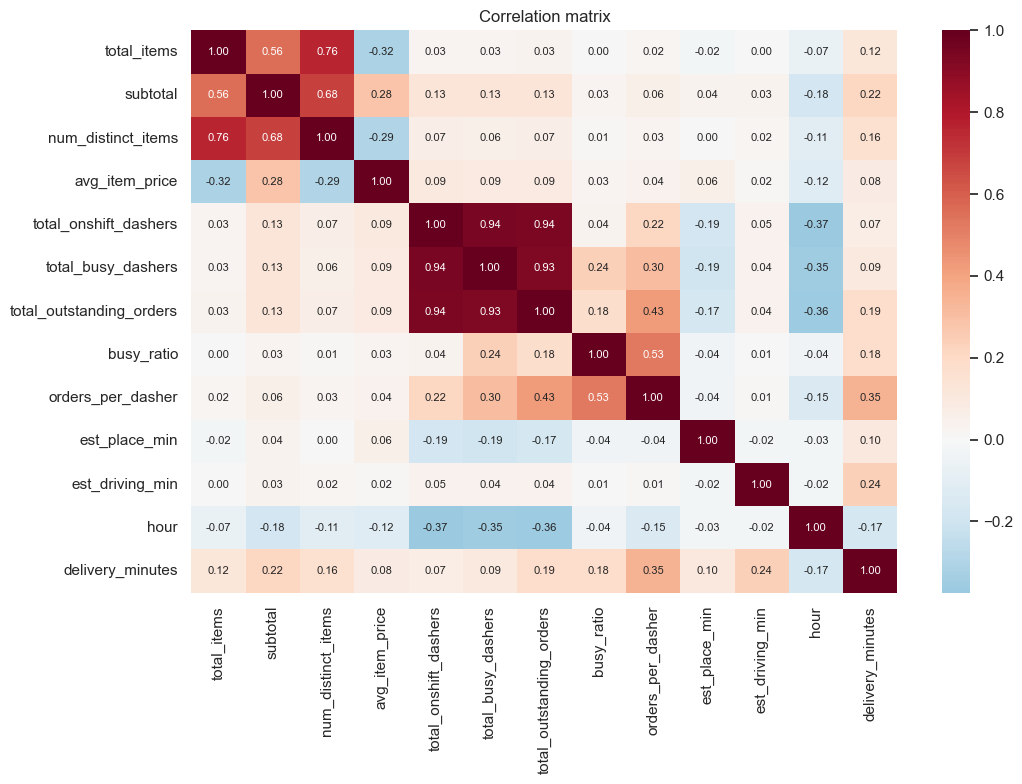

In [15]:
cols = ["total_items", "subtotal", "num_distinct_items", "avg_item_price",
        "total_onshift_dashers", "total_busy_dashers", "total_outstanding_orders",
        "busy_ratio", "orders_per_dasher", "est_place_min", "est_driving_min", "hour", TARGET]
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, annot_kws={"size": 8})
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.savefig("figures/05_correlation.png", dpi=120)
plt.show()

• orders_per_dasher has the strongest correlation with delivery time (0.35). Its raw parts reach only 0.07–0.19. This is direct proof that feature engineering helped.
• The three courier/order counts correlate with each other at 0.93–0.94 (multicollinearity: they all measure "how big the market is right now"). This makes plain linear regression coefficients unstable, so Ridge is added in Step 9.
• No feature is above 0.35, and the load effect is curved. Delivery time depends on many factors at once, non-linearly, which is why tree models are expected to win.

In [16]:
split_idx = int(len(df) * 0.8)          # df is already sorted by created_at
train = df.iloc[:split_idx]
test = df.iloc[split_idx:]

X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

print(f"Train: {len(train):,} orders, {train.created_at.min():%d %b} – {train.created_at.max():%d %b %Y}")
print(f"Test:  {len(test):,} orders, {test.created_at.min():%d %b} – {test.created_at.max():%d %b %Y}")

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Train: 157,826 orders, 21 Jan – 13 Feb 2015
Test:  39,457 orders, 13 Feb – 18 Feb 2015


In [17]:
preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ]), NUMERIC_FEATURES),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), CATEGORICAL_FEATURES),
])

def make_pipe(model):
    return Pipeline([("prep", preprocess), ("model", model)])

In [18]:
ridge_grid = GridSearchCV(
    make_pipe(Ridge()),
    param_grid={"model__alpha": [0.01, 0.1, 1, 10, 100, 1000]},
    cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1,
)
ridge_grid.fit(X_train, y_train)
print("Best alpha:", ridge_grid.best_params_["model__alpha"])

Best alpha: 1000


In [19]:
scoring = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}

candidates = {
    "Baseline (mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Ridge (tuned)": Ridge(alpha=ridge_grid.best_params_["model__alpha"]),
    "Random Forest": RandomForestRegressor(n_estimators=60, max_depth=14, min_samples_leaf=10,
                                           max_features=0.5, max_samples=0.2,
                                           n_jobs=-1, random_state=RANDOM_STATE),
    "LightGBM (default)": LGBMRegressor(random_state=RANDOM_STATE, verbose=-1),
}

rows = []
for name, model in candidates.items():
    start = time.time()
    s = cross_validate(make_pipe(model), X_train, y_train, cv=cv, scoring=scoring)
    rows.append({"Model": name,
                 "CV MAE": -s["test_MAE"].mean(),
                 "MAE std": s["test_MAE"].std(),
                 "CV RMSE": -s["test_RMSE"].mean(),
                 "CV R2": s["test_R2"].mean(),
                 "seconds": time.time() - start})
    print(f"{name:20s} MAE = {-s['test_MAE'].mean():.2f} ± {s['test_MAE'].std():.2f}")

cv_results = pd.DataFrame(rows).round(3)
cv_results

Baseline (mean)      MAE = 13.39 ± 0.06
Linear Regression    MAE = 11.14 ± 0.08
Ridge (tuned)        MAE = 11.14 ± 0.08
Random Forest        MAE = 10.78 ± 0.09


/Users/akmaralazhimamatova/Desktop/Final Project DS/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/akmaralazhimamatova/Desktop/Final Project DS/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/akmaralazhimamatova/Desktop/Final Project DS/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/akmaralazhimamatova/Desktop/Final Project DS/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


LightGBM (default)   MAE = 10.47 ± 0.08


/Users/akmaralazhimamatova/Desktop/Final Project DS/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,Model,CV MAE,MAE std,CV RMSE,CV R2,seconds
0,Baseline (mean),13.392,0.059,17.872,-0.000,1.202
1,Linear Regression,11.138,0.080,15.259,0.271,4.085
2,Ridge (tuned),11.136,0.080,15.275,0.269,1.619
3,Random Forest,10.783,0.090,14.744,0.319,21.571
4,LightGBM (default),10.466,0.083,14.351,0.355,4.570


In [20]:
cv3 = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 200, 800, step=100),
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 15, 127, log=True),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 200, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
    }
    model = make_pipe(LGBMRegressor(**params, subsample_freq=1, random_state=RANDOM_STATE, verbose=-1))
    scores = cross_validate(model, X_train, y_train, cv=cv3, scoring="neg_mean_absolute_error")
    return -scores["test_score"].mean()

study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=20, show_progress_bar=True)

print("Best CV MAE:", round(study.best_value, 3))
print("Best parameters:", study.best_params)

  0%|          | 0/20 [00:00<?, ?it/s]/Users/akmaralazhimamatova/Desktop/Final Project DS/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/akmaralazhimamatova/Desktop/Final Project DS/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/akmaralazhimamatova/Desktop/Final Project DS/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
Best trial: 0. Best value: 10.5959:   5%|▌         | 1/20 [00:14<04:26, 14.03s/it]/Users/akmaralazhimamatova/Desktop/Final Project DS/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but L

Best CV MAE: 10.304
Best parameters: {'n_estimators': 800, 'learning_rate': 0.02070416974614501, 'num_leaves': 113, 'min_child_samples': 14, 'subsample': 0.8845751202275918, 'colsample_bytree': 0.9923282776316165, 'reg_lambda': 0.012146173243762453}


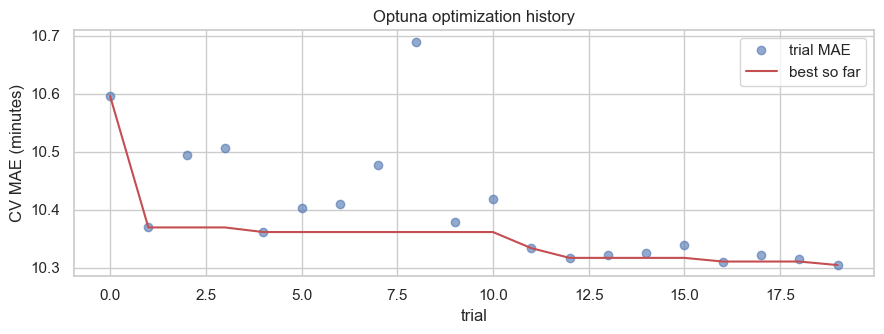

In [21]:
history = study.trials_dataframe()
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(history["number"], history["value"], "o", alpha=0.6, label="trial MAE")
ax.plot(history["number"], history["value"].cummin(), "r-", label="best so far")
ax.set(title="Optuna optimization history", xlabel="trial", ylabel="CV MAE (minutes)")
ax.legend()
plt.tight_layout()
plt.savefig("figures/06_optuna_history.png", dpi=120)
plt.show()

In [22]:
def evaluate(y_true, y_pred):
    error = y_true.values - y_pred
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred),
            "within ±10 min, %": np.mean(np.abs(error) <= 10) * 100,
            "late >10 min, %": np.mean(error > 10) * 100}

final_models = dict(candidates)
final_models["LightGBM (Optuna)"] = LGBMRegressor(**study.best_params, subsample_freq=1,
                                                  random_state=RANDOM_STATE, verbose=-1)

rows, fitted = [], {}
for name, model in final_models.items():
    pipe = make_pipe(model).fit(X_train, y_train)
    fitted[name] = pipe
    rows.append({"Model": name, **evaluate(y_test, pipe.predict(X_test))})

test_results = pd.DataFrame(rows).round(2)
test_results

/Users/akmaralazhimamatova/Desktop/Final Project DS/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/akmaralazhimamatova/Desktop/Final Project DS/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,Model,MAE,RMSE,R2,"within ±10 min, %","late >10 min, %"
0,Baseline (mean),13.91,18.73,-0.02,45.24,27.80
1,Linear Regression,11.55,15.77,0.28,53.81,21.47
2,Ridge (tuned),11.55,15.78,0.28,53.86,21.52
3,Random Forest,11.24,15.57,0.30,56.30,22.51
4,LightGBM (default),10.94,15.22,0.33,57.54,22.05
5,LightGBM (Optuna),10.83,15.10,0.34,58.18,22.03


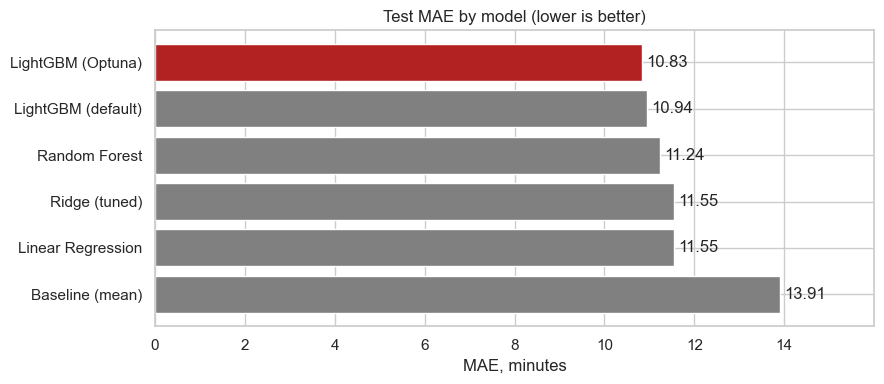

In [23]:
tr = test_results.sort_values("MAE", ascending=False)
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(tr["Model"], tr["MAE"], color=["firebrick" if "Optuna" in m else "grey" for m in tr["Model"]])
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.set(title="Test MAE by model (lower is better)", xlabel="MAE, minutes", xlim=(0, tr["MAE"].max() * 1.15))
plt.tight_layout()
plt.savefig("figures/07_model_comparison.png", dpi=120)
plt.show()

/Users/akmaralazhimamatova/Desktop/Final Project DS/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


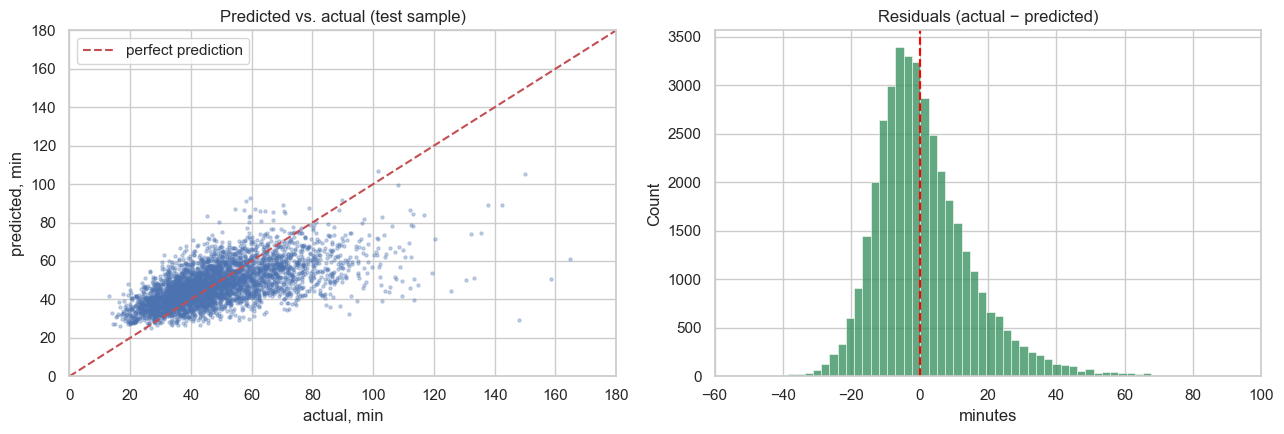

In [24]:
best = fitted["LightGBM (Optuna)"]
pred = best.predict(X_test)
resid = y_test.values - pred

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
idx = np.random.RandomState(0).choice(len(y_test), 4000, replace=False)
axes[0].scatter(y_test.values[idx], pred[idx], s=5, alpha=0.3)
axes[0].plot([0, 180], [0, 180], "r--", label="perfect prediction")
axes[0].set(title="Predicted vs. actual (test sample)", xlabel="actual, min", ylabel="predicted, min",
            xlim=(0, 180), ylim=(0, 180))
axes[0].legend()
sns.histplot(resid, bins=80, ax=axes[1], color="seagreen")
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set(title="Residuals (actual − predicted)", xlabel="minutes", xlim=(-60, 100))
plt.tight_layout()
plt.savefig("figures/08_pred_vs_actual.png", dpi=120)
plt.show()

In [25]:
buckets = pd.cut(y_test, [0, 30, 45, 60, 90, 180])
error_table = (pd.DataFrame({"bucket": buckets, "abs_error": np.abs(resid), "bias": resid})
               .groupby("bucket", observed=True)
               .agg(orders=("abs_error", "size"), MAE=("abs_error", "mean"), mean_bias=("bias", "mean"))
               .round(2))
error_table

,orders,MAE,mean_bias
bucket,,,
"(0, 30]",4409,11.68,-11.65
"(30, 45]",14282,7.49,-5.82
"(45, 60]",11497,7.47,1.57
"(60, 90]",7973,15.77,14.34
"(90, 180]",1296,44.24,43.97


the model is accurate for typical orders (30–60 min, about 65% of orders: error ~7.5 min). It pulls extreme orders toward the middle. Very fast orders get overestimated, and very slow ones are underestimated, because rare delays (kitchen problems, traffic, weather) aren't in the data. 

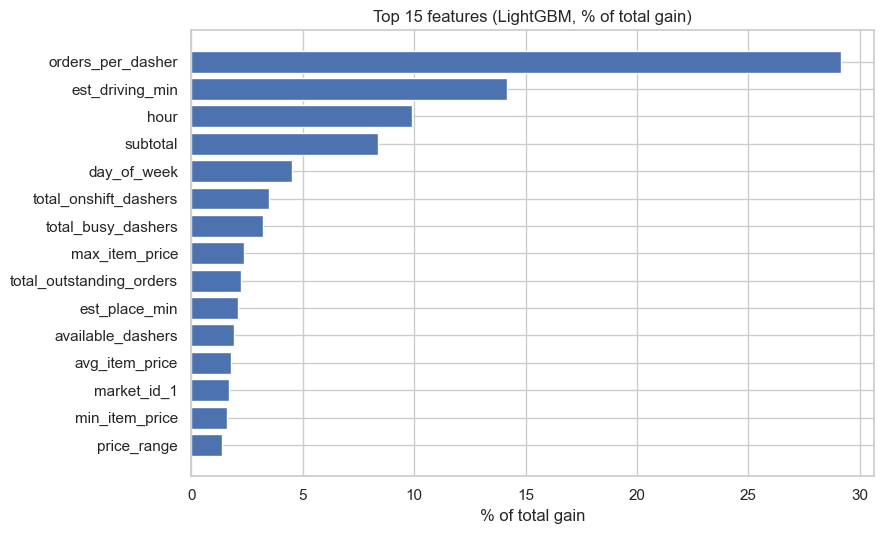

num__orders_per_dasher           29.18
num__est_driving_min             14.17
num__hour                         9.92
num__subtotal                     8.37
num__day_of_week                  4.52
num__total_onshift_dashers        3.49
num__total_busy_dashers           3.20
num__max_item_price               2.38
num__total_outstanding_orders     2.25
num__est_place_min                2.10
num__available_dashers            1.92
num__avg_item_price               1.78
cat__market_id_1                  1.67
num__min_item_price               1.61
num__price_range                  1.37
dtype: float64

In [26]:
names = best.named_steps["prep"].get_feature_names_out()
gain = best.named_steps["model"].booster_.feature_importance(importance_type="gain")
importance = pd.Series(gain / gain.sum() * 100, index=names).sort_values(ascending=False)

top15 = importance.head(15)[::-1]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top15.index.str.replace("num__", "").str.replace("cat__", ""), top15.values)
ax.set(title="Top 15 features (LightGBM, % of total gain)", xlabel="% of total gain")
plt.tight_layout()
plt.savefig("figures/09_feature_importance.png", dpi=120)
plt.show()
importance.head(15).round(2)

In [27]:
ridge = fitted["Ridge (tuned)"]
coef = pd.Series(ridge.named_steps["model"].coef_, index=ridge.named_steps["prep"].get_feature_names_out())
numeric_coef = coef[coef.index.str.startswith("num__") & ~coef.index.str.contains("missingindicator")]
numeric_coef.index = numeric_coef.index.str.replace("num__", "")
numeric_coef.sort_values().round(2).to_frame("minutes per +1 std")

,minutes per +1 std
total_busy_dashers,-4.51
total_onshift_dashers,-4.19
hour,-1.38
day_of_week,-1.19
available_dashers,-0.24
min_item_price,-0.11
max_item_price,0.02
total_items,0.03
price_range,0.11
busy_ratio,0.46


In [28]:
joblib.dump(best, "models/eta_model.joblib")

meta = {
    "test_mae": float(test_results.set_index("Model").loc["LightGBM (Optuna)", "MAE"]),
    "categories": {c: sorted(df[c].unique().tolist()) for c in CATEGORICAL_FEATURES},
    "median_place_duration": float(train["estimated_order_place_duration"].median()),
}
with open("models/meta.json", "w") as f:
    json.dump(meta, f, indent=2)

test.sample(300, random_state=RANDOM_STATE).to_csv("models/demo_orders.csv", index=False)
print("Saved")

Saved
